## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

## Dataset Loading and Initial Inspection

In [2]:
df=pd.read_csv('pipeline_corrosion.csv')
df

,segment_id,measurement_date,measurement_num,age_years,material,diameter_mm,nominal_thickness_mm,coating_type,cathodic_protection,fluid_type,...,corr_rate_lag_3,thickness_change,thickness_change_pct,corr_rate_rolling_3,corr_rate_acceleration,temp_pressure_interaction,flow_watercut_interaction,co2_ph_interaction,days_since_install,days_between_measurements
0,SEG-0001,2005-01-01,1,2.00,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,NaN,NaN,0.001000,NaN,7017.44,439.00,-0.15288,730.5000,NaN
1,SEG-0001,2006-01-24,2,3.06,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,0.014,0.075545,0.001750,0.0015,7813.26,664.62,1.54336,1140.6650,388.0
2,SEG-0001,2007-01-06,3,4.01,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,0.061,0.328912,0.001500,-0.0015,7071.12,2976.00,0.57552,1469.6525,347.0
3,SEG-0001,2007-12-24,4,4.98,X52,609.6,18.63,FBE,1,wet_gas,...,0.0010,0.020,0.107486,0.003667,0.0065,6672.00,1904.00,0.19257,2175.9450,352.0
4,SEG-0001,2008-11-26,5,5.90,X52,609.6,18.63,FBE,1,wet_gas,...,0.0025,-0.076,-0.408010,0.003167,-0.0065,5190.30,2038.11,0.29480,2484.9750,338.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8435,SEG-0250,2022-06-25,19,10.48,X42,609.6,9.50,CTE,1,crude_oil,...,0.0838,0.058,0.745214,0.169667,-0.0725,4098.40,31510.77,4.22464,4002.8200,208.0
8436,SEG-0250,2023-02-17,20,11.13,X42,609.6,9.50,CTE,1,crude_oil,...,0.2251,-0.527,-6.721081,0.169233,0.1181,5041.14,36056.76,5.30400,4112.2325,237.0
8437,SEG-0250,2023-09-06,21,11.68,X42,609.6,9.50,CTE,1,crude_oil,...,0.1782,0.294,4.019688,0.147433,-0.1110,3582.78,35333.44,5.35602,4514.1200,201.0
8438,SEG-0250,2024-04-29,22,12.33,X42,609.6,9.50,CTE,1,crude_oil,...,0.1057,-0.453,-5.954259,0.187900,0.1143,4703.10,34608.60,6.38365,4622.5325,236.0


In [3]:
df.head()

,segment_id,measurement_date,measurement_num,age_years,material,diameter_mm,nominal_thickness_mm,coating_type,cathodic_protection,fluid_type,...,corr_rate_lag_3,thickness_change,thickness_change_pct,corr_rate_rolling_3,corr_rate_acceleration,temp_pressure_interaction,flow_watercut_interaction,co2_ph_interaction,days_since_install,days_between_measurements
0,SEG-0001,2005-01-01,1,2.00,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,NaN,NaN,0.001000,NaN,7017.44,439.00,-0.15288,730.5000,NaN
1,SEG-0001,2006-01-24,2,3.06,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,0.014,0.075545,0.001750,0.0015,7813.26,664.62,1.54336,1140.6650,388.0
2,SEG-0001,2007-01-06,3,4.01,X52,609.6,18.63,FBE,1,wet_gas,...,NaN,0.061,0.328912,0.001500,-0.0015,7071.12,2976.00,0.57552,1469.6525,347.0
3,SEG-0001,2007-12-24,4,4.98,X52,609.6,18.63,FBE,1,wet_gas,...,0.0010,0.020,0.107486,0.003667,0.0065,6672.00,1904.00,0.19257,2175.9450,352.0
4,SEG-0001,2008-11-26,5,5.90,X52,609.6,18.63,FBE,1,wet_gas,...,0.0025,-0.076,-0.408010,0.003167,-0.0065,5190.30,2038.11,0.29480,2484.9750,338.0


In [4]:
df.tail()

,segment_id,measurement_date,measurement_num,age_years,material,diameter_mm,nominal_thickness_mm,coating_type,cathodic_protection,fluid_type,...,corr_rate_lag_3,thickness_change,thickness_change_pct,corr_rate_rolling_3,corr_rate_acceleration,temp_pressure_interaction,flow_watercut_interaction,co2_ph_interaction,days_since_install,days_between_measurements
8435,SEG-0250,2022-06-25,19,10.48,X42,609.6,9.5,CTE,1,crude_oil,...,0.0838,0.058,0.745214,0.169667,-0.0725,4098.40,31510.77,4.22464,4002.8200,208.0
8436,SEG-0250,2023-02-17,20,11.13,X42,609.6,9.5,CTE,1,crude_oil,...,0.2251,-0.527,-6.721081,0.169233,0.1181,5041.14,36056.76,5.30400,4112.2325,237.0
8437,SEG-0250,2023-09-06,21,11.68,X42,609.6,9.5,CTE,1,crude_oil,...,0.1782,0.294,4.019688,0.147433,-0.1110,3582.78,35333.44,5.35602,4514.1200,201.0
8438,SEG-0250,2024-04-29,22,12.33,X42,609.6,9.5,CTE,1,crude_oil,...,0.1057,-0.453,-5.954259,0.187900,0.1143,4703.10,34608.60,6.38365,4622.5325,236.0
8439,SEG-0250,2024-11-21,23,12.89,X42,609.6,9.5,CTE,1,crude_oil,...,0.2238,0.222,3.102725,0.138600,-0.1512,4107.43,34214.70,4.97827,5033.0725,206.0


In [5]:
df.shape

(8440, 48)

In [6]:
df.columns

Index(['segment_id', 'measurement_date', 'measurement_num', 'age_years',
       'material', 'diameter_mm', 'nominal_thickness_mm', 'coating_type',
       'cathodic_protection', 'fluid_type', 'corrosion_mechanism', 'seam_type',
       'temperature_c', 'pressure_bar', 'flow_rate_m3h', 'pH',
       'co2_partial_pressure_bar', 'h2s_ppm', 'water_cut_pct',
       'inhibitor_dose_ppm', 'chloride_ppm', 'dissolved_o2_ppb',
       'coating_condition', 'measured_thickness_mm', 'corrosion_rate_mm_yr',
       'cumulative_thickness_loss_mm', 'normalized_thickness',
       'remaining_useful_life_years', 'retirement_thickness_mm', 'alert_level',
       'month', 'year', 'quarter', 'thickness_lag_1', 'corr_rate_lag_1',
       'thickness_lag_2', 'corr_rate_lag_2', 'thickness_lag_3',
       'corr_rate_lag_3', 'thickness_change', 'thickness_change_pct',
       'corr_rate_rolling_3', 'corr_rate_acceleration',
       'temp_pressure_interaction', 'flow_watercut_interaction',
       'co2_ph_interaction', 'days

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8440 entries, 0 to 8439
Data columns (total 48 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   segment_id                    8440 non-null   object 
 1   measurement_date              8440 non-null   object 
 2   measurement_num               8440 non-null   int64  
 3   age_years                     8440 non-null   float64
 4   material                      8440 non-null   object 
 5   diameter_mm                   8440 non-null   float64
 6   nominal_thickness_mm          8440 non-null   float64
 7   coating_type                  8440 non-null   object 
 8   cathodic_protection           8440 non-null   int64  
 9   fluid_type                    8440 non-null   object 
 10  corrosion_mechanism           8440 non-null   object 
 11  seam_type                     8440 non-null   object 
 12  temperature_c                 8440 non-null   float64
 13  pre

In [8]:
df.describe

<bound method NDFrame.describe of      segment_id measurement_date  measurement_num  age_years material  \
0      SEG-0001       2005-01-01                1       2.00      X52   
1      SEG-0001       2006-01-24                2       3.06      X52   
2      SEG-0001       2007-01-06                3       4.01      X52   
3      SEG-0001       2007-12-24                4       4.98      X52   
4      SEG-0001       2008-11-26                5       5.90      X52   
...         ...              ...              ...        ...      ...   
8435   SEG-0250       2022-06-25               19      10.48      X42   
8436   SEG-0250       2023-02-17               20      11.13      X42   
8437   SEG-0250       2023-09-06               21      11.68      X42   
8438   SEG-0250       2024-04-29               22      12.33      X42   
8439   SEG-0250       2024-11-21               23      12.89      X42   

      diameter_mm  nominal_thickness_mm coating_type  cathodic_protection  \
0           

## Exploratory Data Analysis (EDA)

In [9]:
features = ['segment_id', 'measurement_date','age_years','material','diameter_mm','nominal_thickness_mm','coating_type','cathodic_protection','fluid_type','corrosion_mechanism','seam_type','temperature_c',
'pressure_bar','flow_rate_m3h','pH','co2_partial_pressure_bar','h2s_ppm','water_cut_pct','inhibitor_dose_ppm','chloride_ppm','dissolved_o2_ppb','coating_condition','measured_thickness_mm',
'corr_rate_lag_1','thickness_lag_1', 'corr_rate_lag_2','corrosion_rate_mm_yr']

In [10]:
df1=df[features]

In [11]:
df1.shape

(8440, 27)

#### Numerical and Categorical Features

In [12]:
numerical_columns=df1.select_dtypes(include=np.number).columns
catogorical_columns=df1.select_dtypes(include=['object','category']).columns

In [13]:
numerical_columns

Index(['age_years', 'diameter_mm', 'nominal_thickness_mm',
       'cathodic_protection', 'temperature_c', 'pressure_bar', 'flow_rate_m3h',
       'pH', 'co2_partial_pressure_bar', 'h2s_ppm', 'water_cut_pct',
       'inhibitor_dose_ppm', 'chloride_ppm', 'dissolved_o2_ppb',
       'coating_condition', 'measured_thickness_mm', 'corr_rate_lag_1',
       'thickness_lag_1', 'corr_rate_lag_2', 'corrosion_rate_mm_yr'],
      dtype='object')

In [14]:
catogorical_columns

Index(['segment_id', 'measurement_date', 'material', 'coating_type',
       'fluid_type', 'corrosion_mechanism', 'seam_type'],
      dtype='object')

#### Numerical Feature Distribution

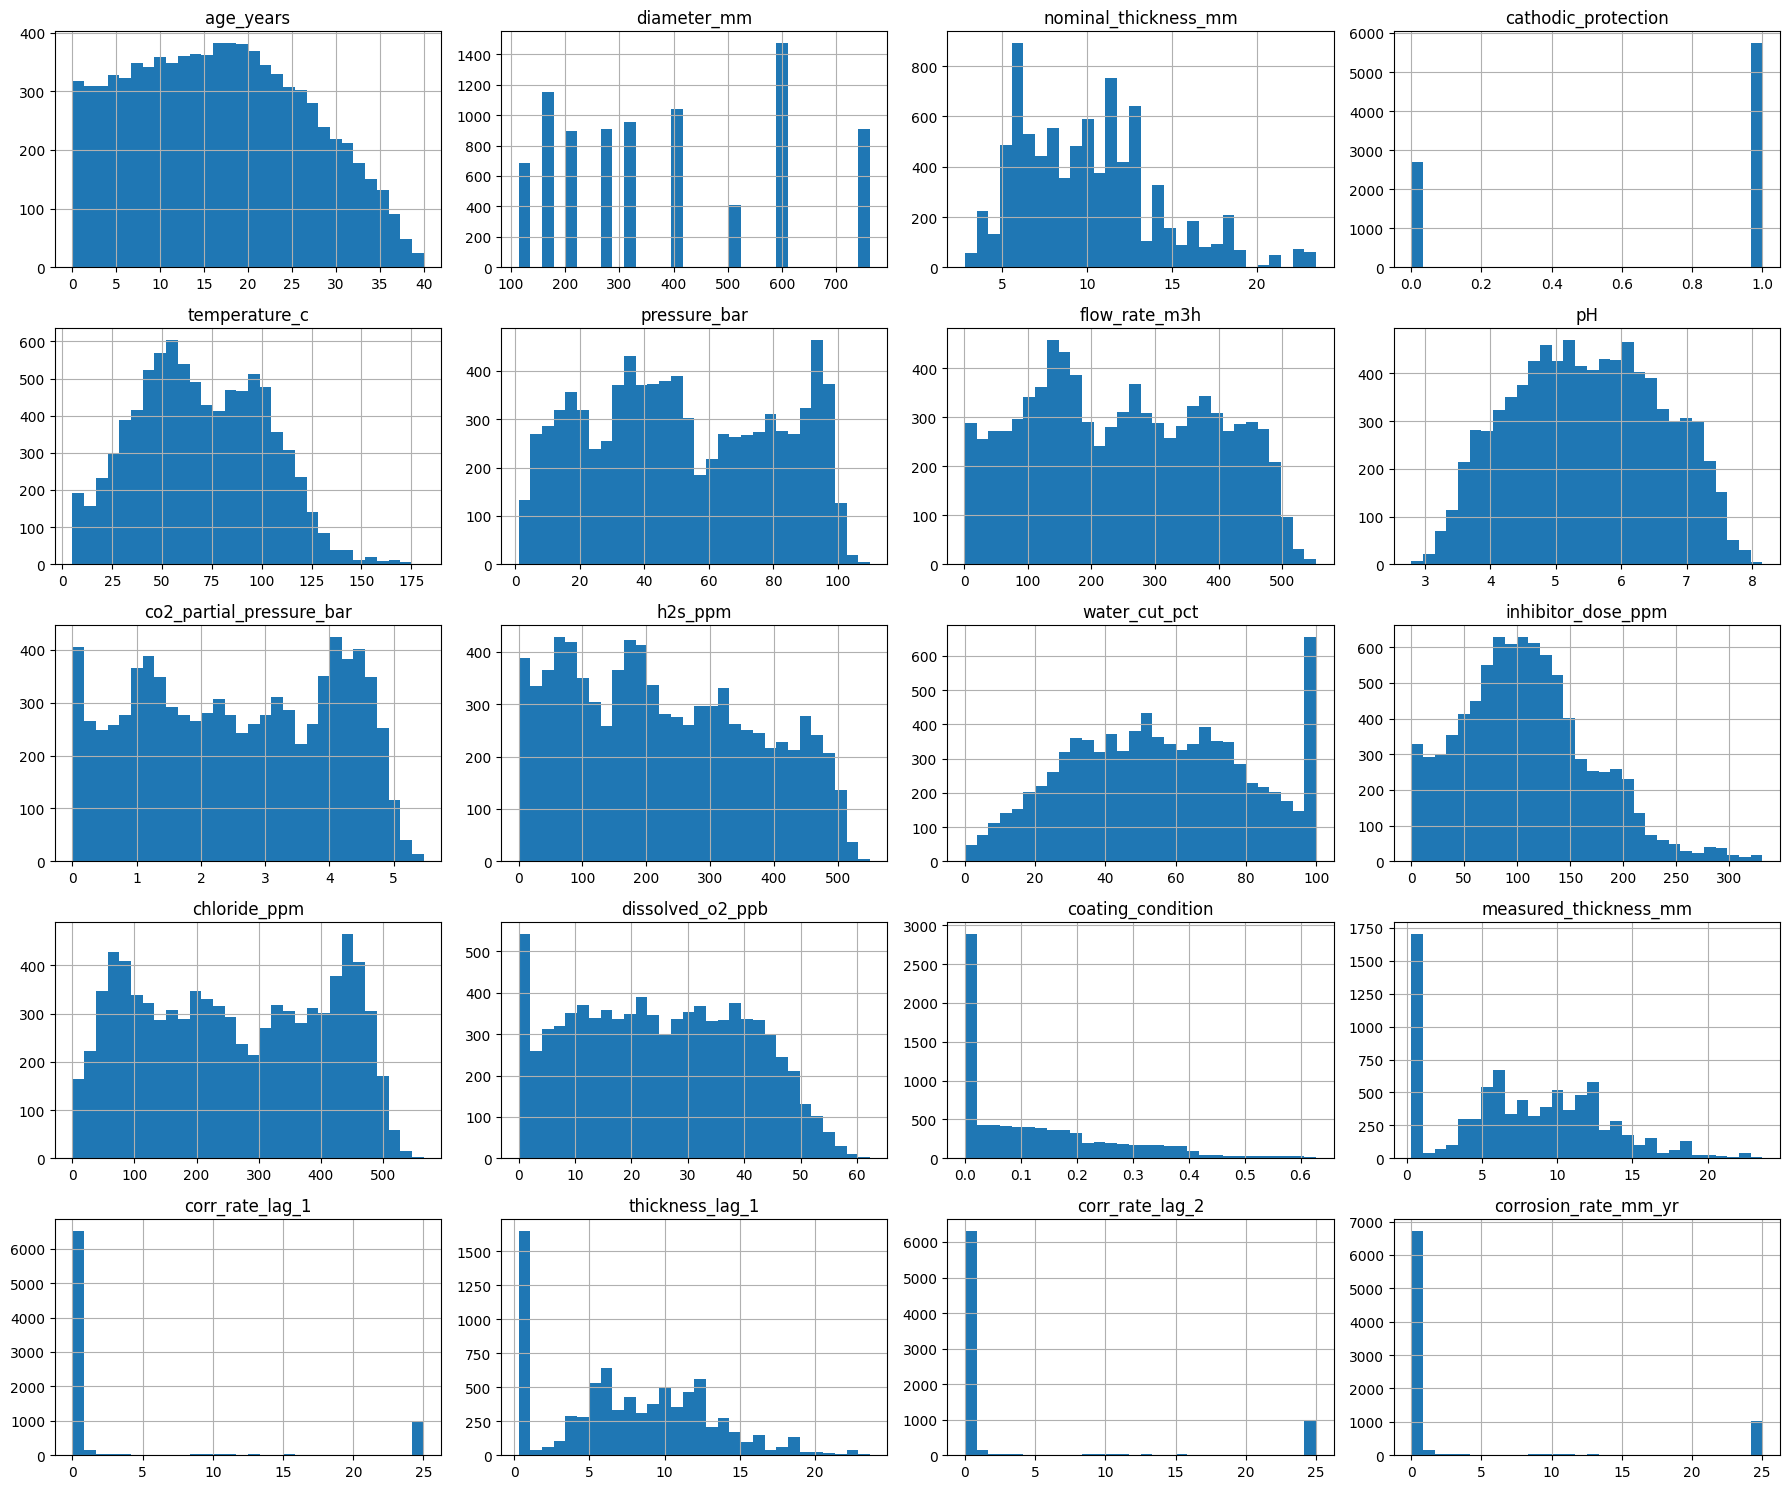

In [15]:
df1[numerical_columns].hist(figsize=(18, 15),bins=30)
plt.tight_layout()
plt.show()

#### Correlation Analysis

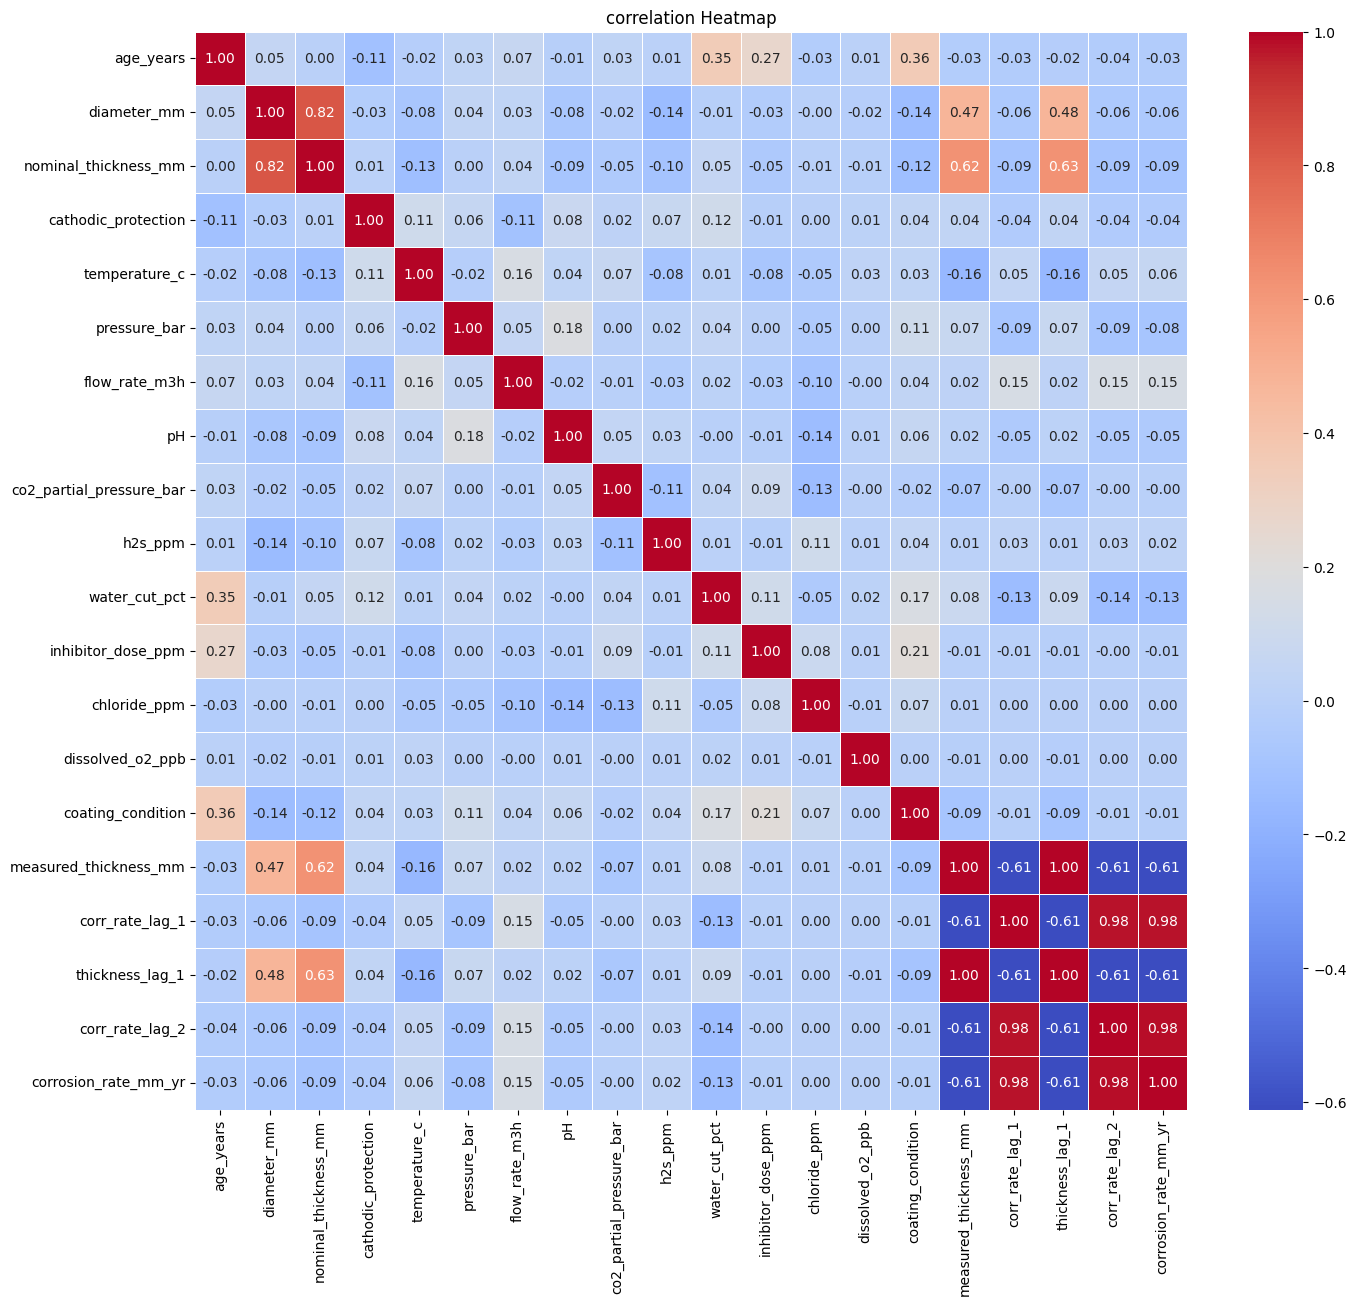

In [16]:
correlation=df1[numerical_columns].corr()
plt.figure(figsize=(16,14))
sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f',linewidths=0.5)
plt.title('correlation Heatmap')
plt.show()

#### Missing Value Analysis

In [17]:
df1.isnull().sum()

segment_id                    0
measurement_date              0
age_years                     0
material                      0
diameter_mm                   0
nominal_thickness_mm          0
coating_type                  0
cathodic_protection           0
fluid_type                    0
corrosion_mechanism           0
seam_type                     0
temperature_c                 0
pressure_bar                  0
flow_rate_m3h                 0
pH                            0
co2_partial_pressure_bar      0
h2s_ppm                       0
water_cut_pct                 0
inhibitor_dose_ppm            0
chloride_ppm                  0
dissolved_o2_ppb              0
coating_condition             0
measured_thickness_mm         0
corr_rate_lag_1             250
thickness_lag_1             250
corr_rate_lag_2             500
corrosion_rate_mm_yr          0
dtype: int64

In [18]:
missing = pd.DataFrame({
    "Missing_Count": df1.isnull().sum(),
    "Missing_Percentage": df1.isnull().mean() * 100
})

print(missing[missing["Missing_Count"] > 0])

                 Missing_Count  Missing_Percentage
corr_rate_lag_1            250            2.962085
thickness_lag_1            250            2.962085
corr_rate_lag_2            500            5.924171


#### Outlier Analysis

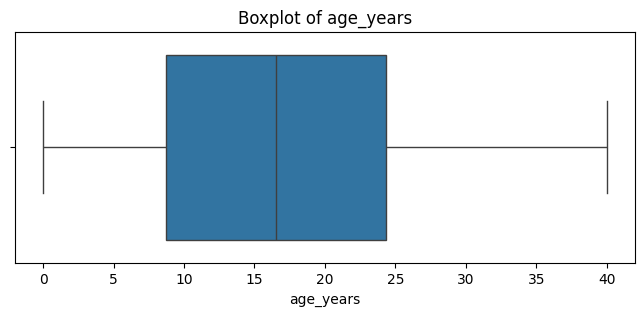

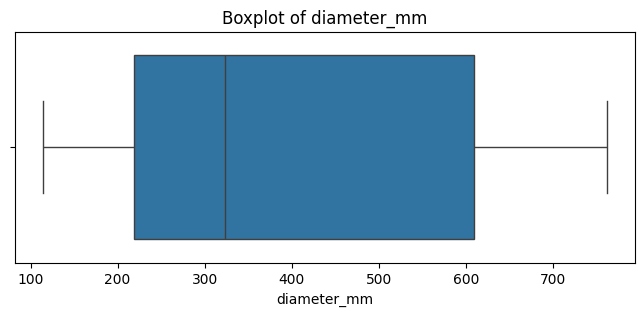

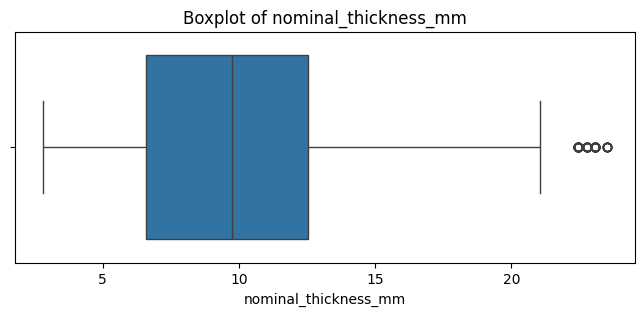

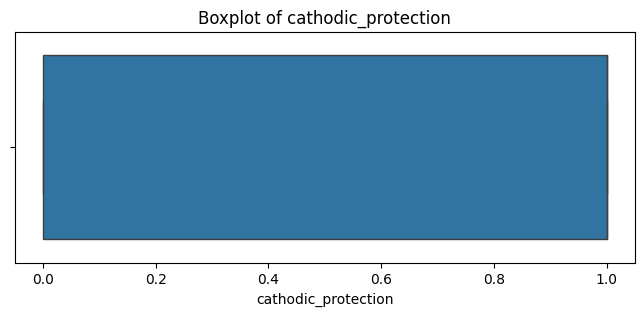

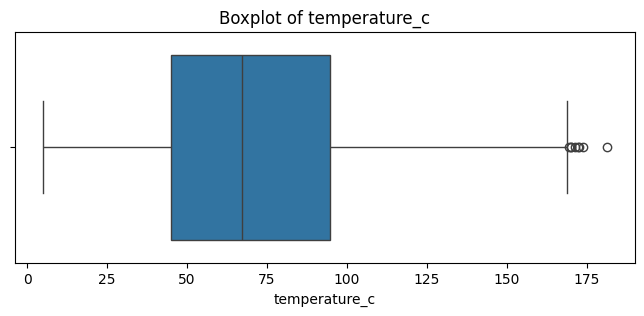

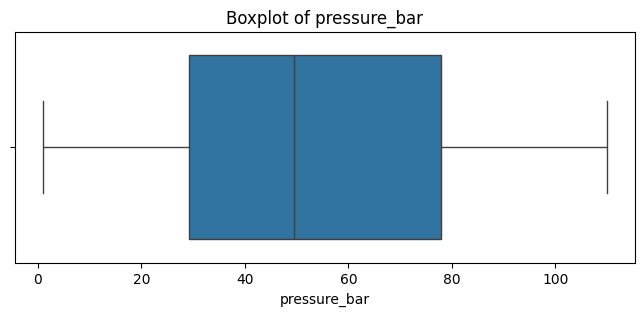

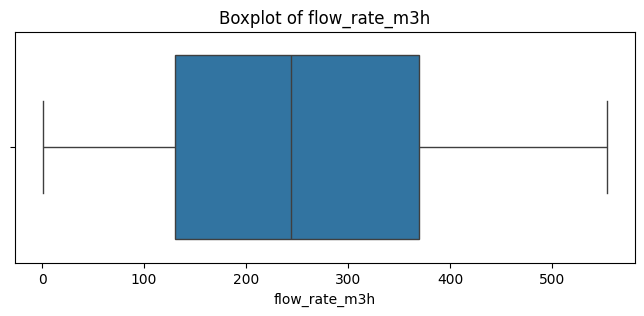

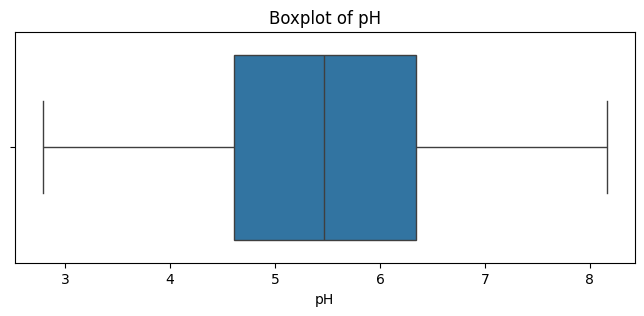

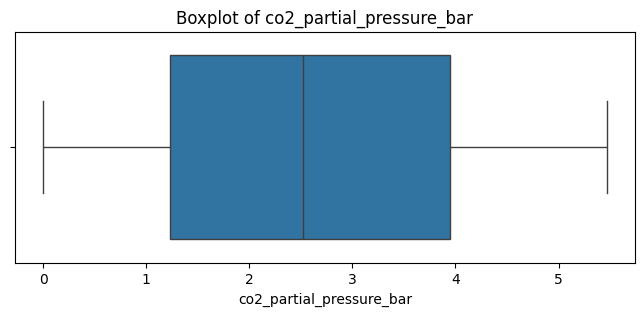

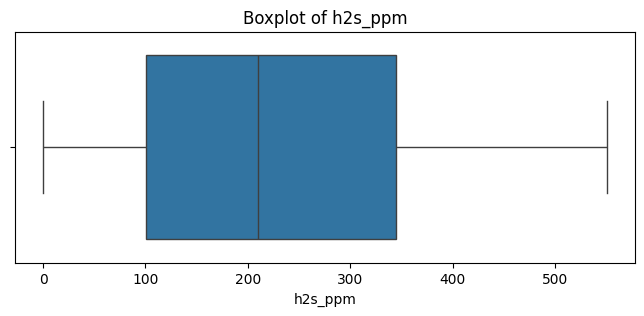

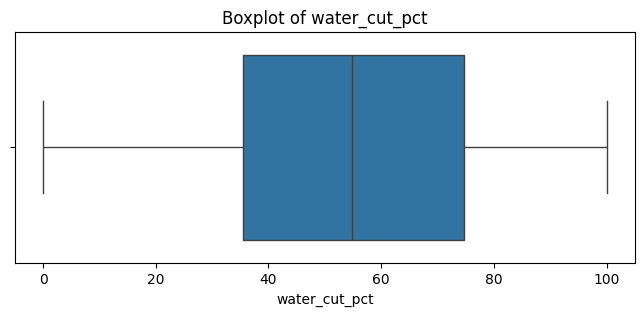

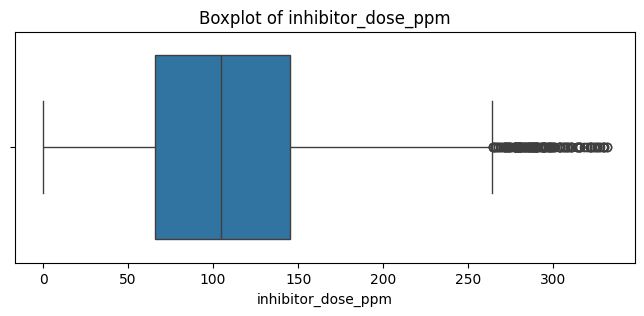

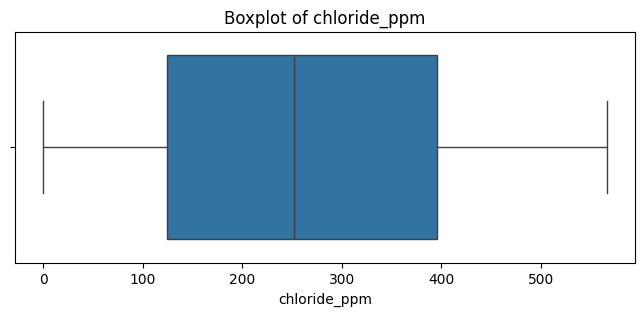

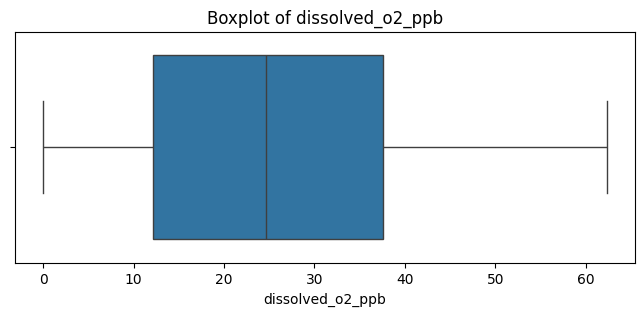

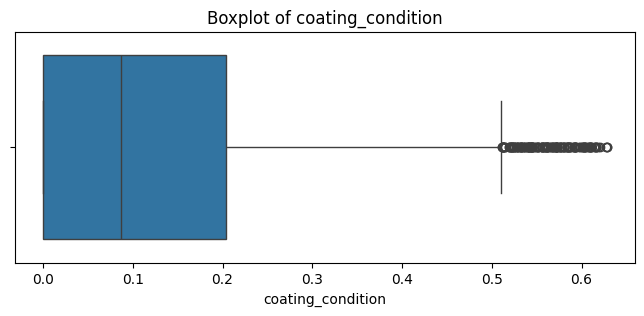

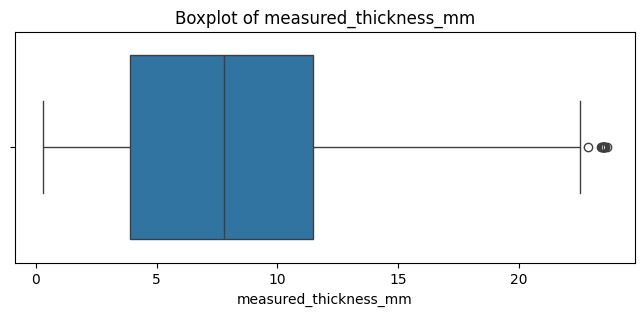

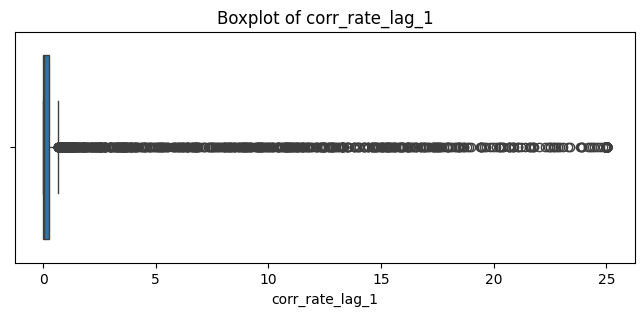

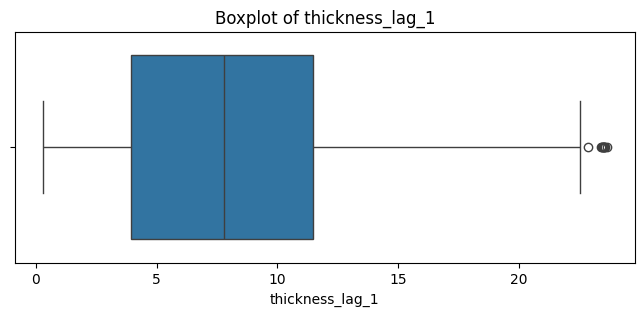

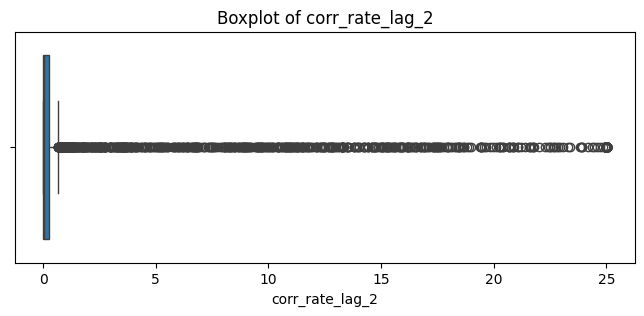

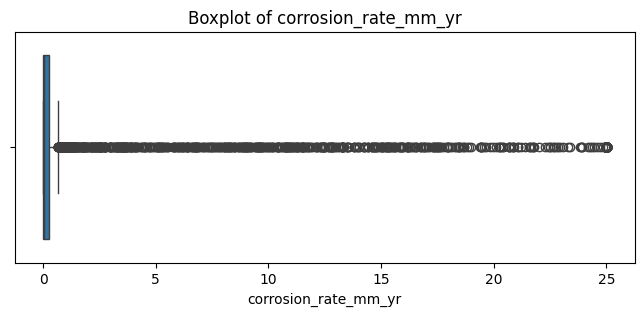

In [19]:
for col in numerical_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df1[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [20]:
for col in numerical_columns:
    Q1 = df1[col].quantile(0.25)
    Q3 = df1[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df1[col] < lower) |
             (df1[col] > upper)).sum()

    print(col, ":", count)

age_years : 0
diameter_mm : 0
nominal_thickness_mm : 133
cathodic_protection : 0
temperature_c : 8
pressure_bar : 0
flow_rate_m3h : 0
pH : 0
co2_partial_pressure_bar : 0
h2s_ppm : 0
water_cut_pct : 0
inhibitor_dose_ppm : 150
chloride_ppm : 0
dissolved_o2_ppb : 0
coating_condition : 158
measured_thickness_mm : 11
corr_rate_lag_1 : 1732
thickness_lag_1 : 10
corr_rate_lag_2 : 1676
corrosion_rate_mm_yr : 1780


In [21]:
check_cols = ['nominal_thickness_mm','inhibitor_dose_ppm','coating_condition','corr_rate_lag_1','corr_rate_lag_2','corrosion_rate_mm_yr']
for col in check_cols:
    print("\n", col)
    print(df1[col].describe())


 nominal_thickness_mm
count    8440.000000
mean       10.105521
std         4.101488
min         2.810000
25%         6.580000
50%         9.760000
75%        12.530000
max        23.500000
Name: nominal_thickness_mm, dtype: float64

 inhibitor_dose_ppm
count    8440.000000
mean      109.290960
std        61.703483
min         0.000000
25%        65.800000
50%       104.700000
75%       145.100000
max       331.400000
Name: inhibitor_dose_ppm, dtype: float64

 coating_condition
count    8440.000000
mean        0.127966
std         0.140011
min         0.000000
25%         0.000000
50%         0.087000
75%         0.204000
max         0.628000
Name: coating_condition, dtype: float64

 corr_rate_lag_1
count    8190.000000
mean        3.760962
std         8.411687
min         0.001000
25%         0.005900
50%         0.024800
75%         0.268800
max        25.015200
Name: corr_rate_lag_1, dtype: float64

 corr_rate_lag_2
count    7940.000000
mean        3.779124
std         8.432565
min

#### Target Variable Distribution

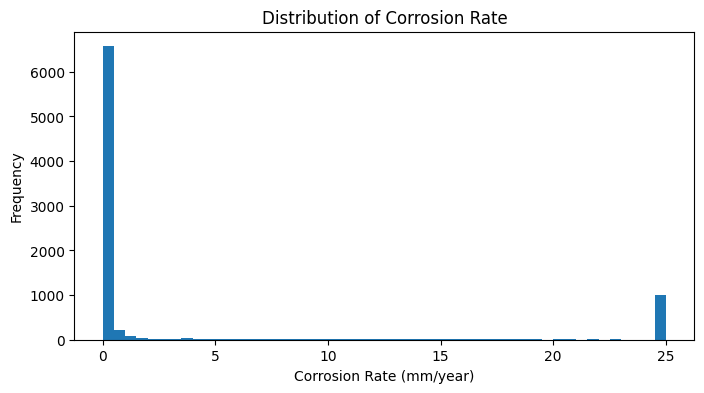

In [22]:
plt.figure(figsize=(8, 4))
plt.hist(df1['corrosion_rate_mm_yr'], bins=50)
plt.xlabel('Corrosion Rate (mm/year)')
plt.ylabel('Frequency')
plt.title('Distribution of Corrosion Rate')
plt.show()

#### Log-Transformed Target Distribution

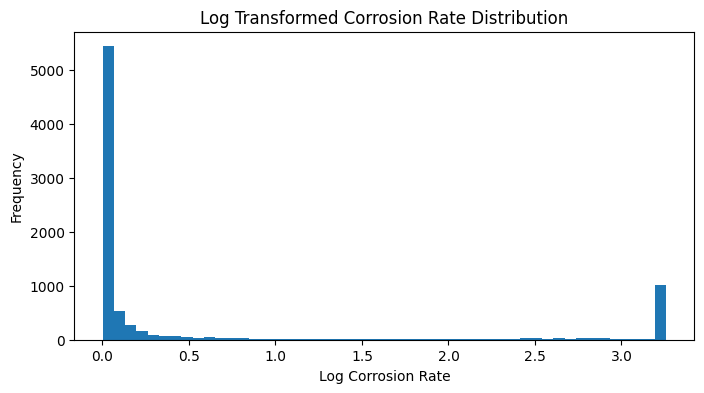

In [23]:
plt.figure(figsize=(8, 4))
plt.hist(np.log1p(df1['corrosion_rate_mm_yr']),bins=50)
plt.xlabel('Log Corrosion Rate')
plt.ylabel('Frequency')
plt.title('Log Transformed Corrosion Rate Distribution')
plt.show()

#### Material vs Corrosion Rate

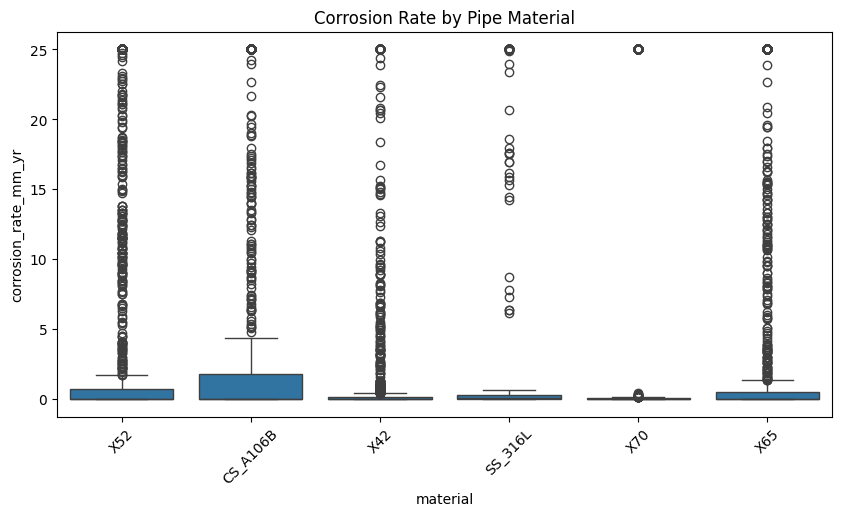

In [24]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df1,x='material',y='corrosion_rate_mm_yr')
plt.title('Corrosion Rate by Pipe Material')
plt.xticks(rotation=45)
plt.show()

#### Corrosion Mechanism vs Corrosion Rate

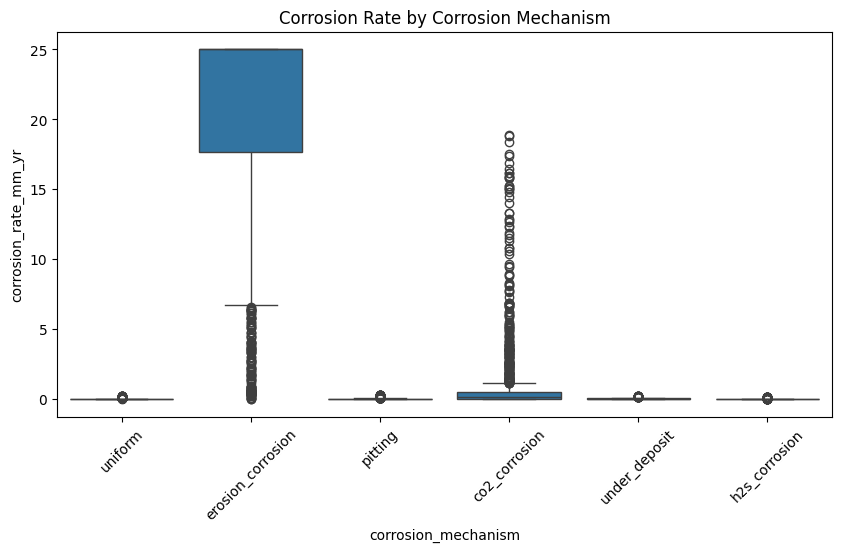

In [25]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df1,x='corrosion_mechanism',y='corrosion_rate_mm_yr')
plt.title('Corrosion Rate by Corrosion Mechanism')
plt.xticks(rotation=45)
plt.show()

#### Temperature vs Corrosion Rate

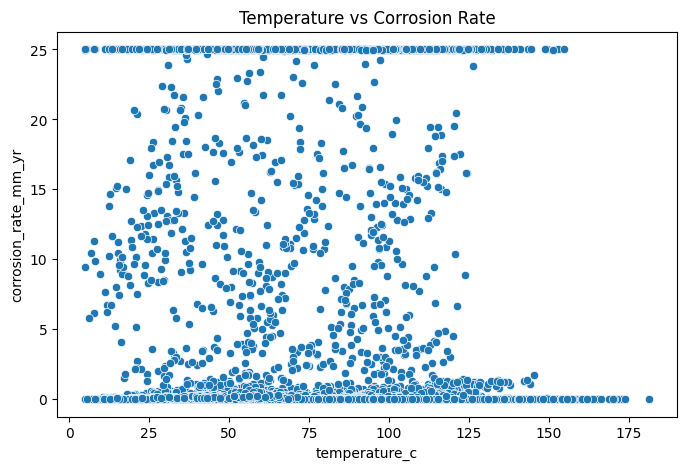

In [27]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df1,x='temperature_c',y='corrosion_rate_mm_yr')
plt.title('Temperature vs Corrosion Rate')
plt.show()

#### Pressure vs Corrosion Rate

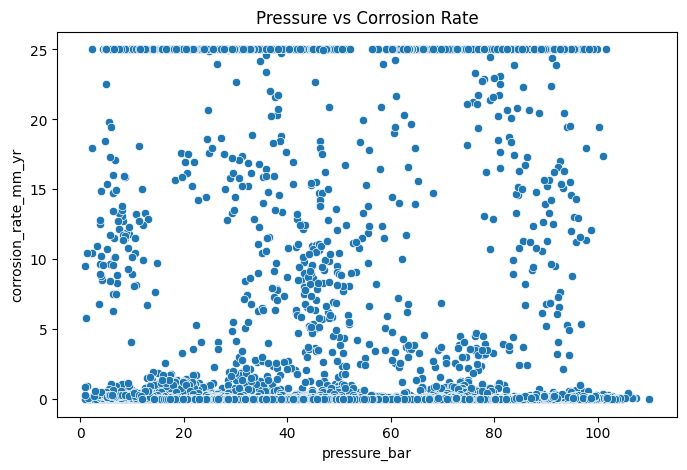

In [28]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df1,x='pressure_bar',y='corrosion_rate_mm_yr')
plt.title('Pressure vs Corrosion Rate')
plt.show()

## Data Cleaning and Preprocessing

#### Handling Missing Values

In [29]:
missing = pd.DataFrame({
    "Missing_Count": df1.isnull().sum(),
    "Missing_Percentage": df1.isnull().mean() * 100
})

print(missing[missing["Missing_Count"] > 0])

In [ ]:
lag_cols = ['corr_rate_lag_1','thickness_lag_1','corr_rate_lag_2']

In [ ]:
df_clean=df1.dropna(subset=lag_cols).copy()

In [ ]:
print("Orginal shape:",df1.shape)
print("cleaned shape:",df_clean.shape)

In [ ]:
df_clean.isnull().sum()

In [ ]:
num_cols=df_clean.select_dtypes(include=np.number).columns
num_cols

In [ ]:
correlation = df_clean[num_cols].corr()
correlation['corrosion_rate_mm_yr'].sort_values(ascending=False)

## Feature Selection and Engineering

#### Identifying the Target Variable

In [ ]:
target="corrosion_rate_mm_yr"

#### Separating Features and Target

In [ ]:
X = df_clean.drop(columns=[target, 'segment_id', 'measurement_date'])
y = df_clean[target]

In [ ]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns

In [ ]:
cat_cols

#### Categorical Feature Encoding

In [ ]:
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)
bool_cols = X_encoded.select_dtypes(include='bool').columns
X_encoded[bool_cols] = X_encoded[bool_cols].astype(int)

In [ ]:
print("Original X shape:", X.shape)
print("Encoded X shape:", X_encoded.shape)
X_encoded.head()

In [ ]:
print(X_encoded.dtypes.value_counts())
X_encoded.head()

## Group-Based Train-Test Split

In [ ]:
groups=df_clean['segment_id']
print(groups.head())
print("Unique pipeline segments:", groups.nunique())

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

In [ ]:
split=GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
train,test=next(split.split(X_encoded,groups=groups))
X_train,X_test=X_encoded.iloc[train], X_encoded.iloc[test]
y_train,y_test=y.iloc[train], y.iloc[test]

In [ ]:
print("train:", X_train.shape, y_train.shape)
print("test:", X_test.shape, y_test.shape)

## Baseline Model Development

In [ ]:
from sklearn.ensemble import RandomForestRegressor

#### Random Forest with Historical Lag Features

In [ ]:
rfg_model=RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=-1)
rfg_model.fit(X_train,y_train)
print("Random Forest model trained successfully!")

#### Baseline Model Evaluation

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
y_pred = rfg_model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)